In [1]:
import torch

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
x = torch.linspace(-3, 3, 120).unsqueeze(1)

In [4]:
x

tensor([[-3.0000],
        [-2.9496],
        [-2.8992],
        [-2.8487],
        [-2.7983],
        [-2.7479],
        [-2.6975],
        [-2.6471],
        [-2.5966],
        [-2.5462],
        [-2.4958],
        [-2.4454],
        [-2.3950],
        [-2.3445],
        [-2.2941],
        [-2.2437],
        [-2.1933],
        [-2.1429],
        [-2.0924],
        [-2.0420],
        [-1.9916],
        [-1.9412],
        [-1.8908],
        [-1.8403],
        [-1.7899],
        [-1.7395],
        [-1.6891],
        [-1.6387],
        [-1.5882],
        [-1.5378],
        [-1.4874],
        [-1.4370],
        [-1.3866],
        [-1.3361],
        [-1.2857],
        [-1.2353],
        [-1.1849],
        [-1.1345],
        [-1.0840],
        [-1.0336],
        [-0.9832],
        [-0.9328],
        [-0.8824],
        [-0.8319],
        [-0.7815],
        [-0.7311],
        [-0.6807],
        [-0.6303],
        [-0.5798],
        [-0.5294],
        [-0.4790],
        [-0.4286],
        [-0.

In [5]:
noise = torch.randn(x.size()) * 0.5
y = 3 * x + 2 + noise

In [6]:
import matplotlib.pyplot as plt

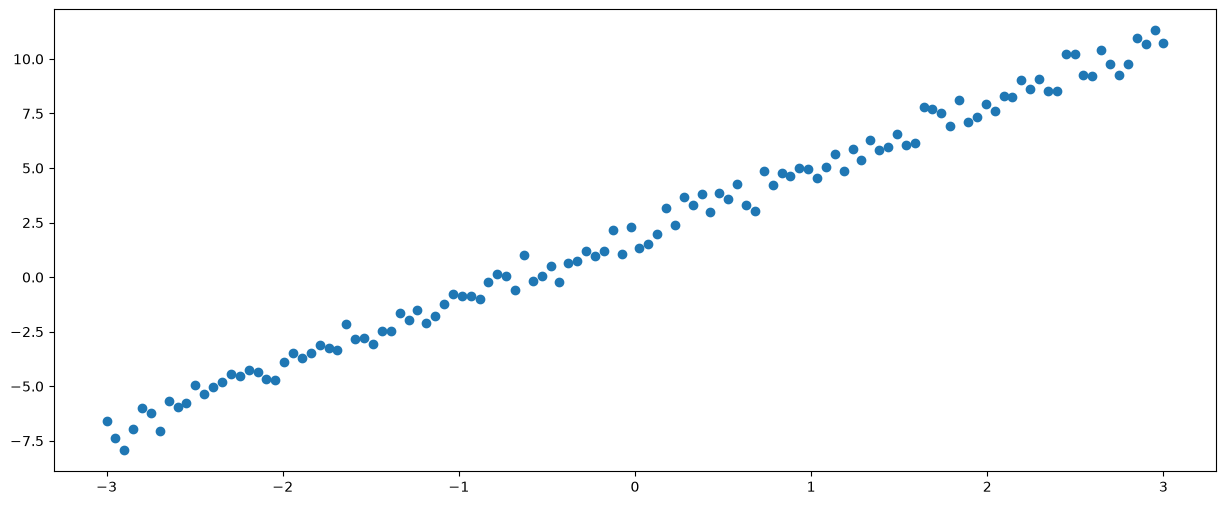

In [7]:
plt.figure(figsize=(15, 6))
plt.scatter(x, y)

In [8]:
import torch.nn as nn

In [9]:
model = nn.Linear(1, 1)

In [10]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
epochs = 500 
losses = []
for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_function(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    
    if (epoch ) % 100 == 0:
        print(f'Epoch [{epoch}/{epochs}], Loss: {loss.item():.4f}')   

Epoch [0/500], Loss: 46.3035
Epoch [100/500], Loss: 25.0063
Epoch [200/500], Loss: 12.5827
Epoch [300/500], Loss: 5.8519
Epoch [400/500], Loss: 2.5103


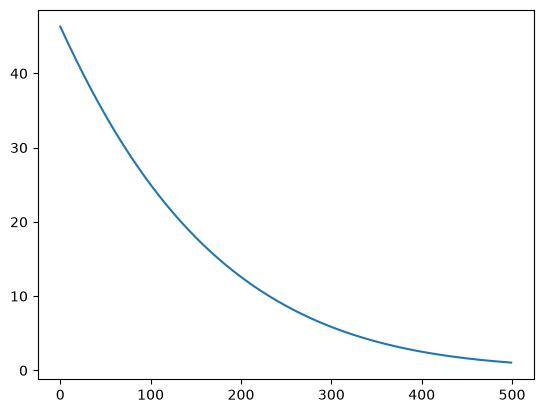

In [11]:
plt.plot(losses)

In [12]:
with torch.inference_mode():
    pred = model(x)

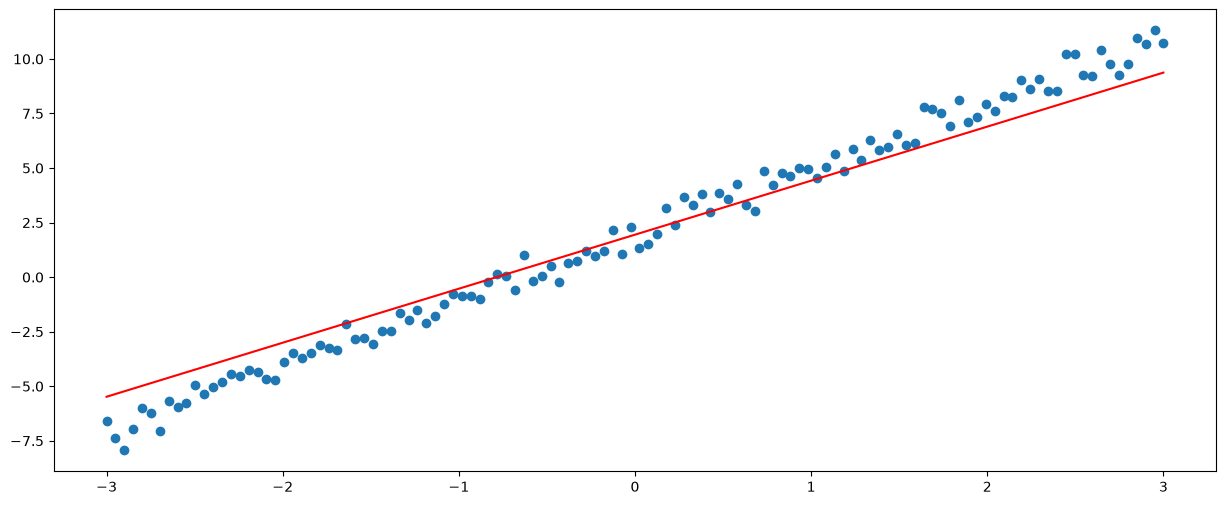

In [13]:
plt.figure(figsize=(15, 6))
plt.scatter(x, y)
plt.plot(x, pred, color='red', label='Regression line')

In [14]:
from torcheval.metrics import R2Score

/Users/iksi/Documents/S9/Generative AI/lab_pytorch_v1/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [15]:
r2_score = R2Score()
r2_score.update(pred, y)
print(f'R2 Score: {r2_score.compute().item():.4f}')

R2 Score: 0.9624
